# 02 — Siachen preprocessing & first velocity maps
Pakistan Glacier Intelligence Explorer · NASA Space Apps 2026 · *Dancing with the SARs*

**Part A — ITS_LIVE (2017–2022, historical baseline)**
1. Crop all 42 annual rasters to the Siachen area of interest (AOI)
2. Quality-filter pixels using `v_error` and `count`
3. Annual statistics, 2017→2022 change map and per-pixel linear trend

**Part B — NISAR GOFF (2025–26, recent radar observations)**

4. Crop every GOFF pair on track 135 / frame 71 to the AOI (new downloads are picked up automatically)
5. Cull outliers (water/invalid mask, SNR, magnitude, local-median consistency)
6. Remove the stable-ground bias (rock should not move)
7. Convert along-track + slant-range offsets → horizontal east/north velocity using the product's own radar geometry
8. Compare against ITS_LIVE and save GeoTIFFs + figures

All outputs → `processed/` (GeoTIFFs) and `results/` (CSV tables, `results/figures/*.png`).
Original files in `data/` are never modified.

In [1]:
from pathlib import Path
import re, datetime as dt
import numpy as np
import pandas as pd
import h5py
import rasterio
from rasterio.windows import from_bounds
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
import matplotlib
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

PROJECT_DIR = Path(r"D:\Pakistan Glacier Intelligence Explorer")
ITS_LIVE_DIR = PROJECT_DIR / "data" / "its_live"
NISAR_DIR    = PROJECT_DIR / "data" / "nisar"
PROC_ITS     = PROJECT_DIR / "processed" / "its_live_siachen"
PROC_NISAR   = PROJECT_DIR / "processed" / "nisar_siachen"
RESULTS      = PROJECT_DIR / "results"
FIGS         = RESULTS / "figures"
for d in (PROC_ITS, PROC_NISAR, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# Siachen Glacier area of interest (WGS84). Includes main trunk + major tributaries.
AOI = dict(lon_min=76.75, lon_max=77.30, lat_min=35.15, lat_max=35.70)
YEARS = list(range(2017, 2023))
VARS = ["v", "vx", "vy", "v_error", "vx_error", "vy_error", "count"]

# NISAR frame we are building a time series on
NISAR_TRACK, NISAR_FRAME, NISAR_PASS = 135, 71, "D"

def aoi_bounds_in(crs):
    t = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    lons = np.linspace(AOI["lon_min"], AOI["lon_max"], 25)
    lats = np.linspace(AOI["lat_min"], AOI["lat_max"], 25)
    LO, LA = np.meshgrid(lons, lats)
    x, y = t.transform(LO.ravel(), LA.ravel())
    return min(x), min(y), max(x), max(y)

def save_tif(path, arr, transform, crs, nodata=np.nan):
    arr = np.asarray(arr, dtype="float32")
    with rasterio.open(path, "w", driver="GTiff", height=arr.shape[0], width=arr.shape[1],
                       count=1, dtype="float32", crs=crs, transform=transform,
                       nodata=nodata, compress="deflate") as dst:
        dst.write(arr, 1)

def nan_median_filter(a, size=5):
    pad = size // 2
    p = np.pad(a, pad, mode="constant", constant_values=np.nan)
    return np.nanmedian(sliding_window_view(p, (size, size)), axis=(-1, -2))

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9})
print("Setup OK")

Setup OK


## Part A — ITS_LIVE
### A1. Crop all 42 rasters to the Siachen AOI

In [2]:
its = {}          # its[var] -> array (year, rows, cols)
for var in VARS:
    stack = []
    for year in YEARS:
        f = ITS_LIVE_DIR / str(year) / f"ITS_LIVE_velocity_120m_RGI14A_{year}_V02.1_{var}.tif"
        with rasterio.open(f) as src:
            if var == VARS[0] and year == YEARS[0]:
                ITS_CRS = src.crs
                win = from_bounds(*aoi_bounds_in(src.crs), src.transform).round_offsets().round_lengths()
                ITS_TRANSFORM = src.window_transform(win)
            a = src.read(1, window=win).astype("float64")
            if src.nodata is not None:
                a[a == src.nodata] = np.nan
        save_tif(PROC_ITS / f"siachen_{year}_{var}.tif", a, ITS_TRANSFORM, ITS_CRS)
        stack.append(a)
    its[var] = np.stack(stack)

print("ITS_LIVE AOI grid:", its["v"].shape[1:], "pixels at 120 m  | CRS", ITS_CRS)
print("Cropped GeoTIFFs written:", len(list(PROC_ITS.glob("*.tif"))), "→", PROC_ITS)

ITS_LIVE AOI grid: (531, 467) pixels at 120 m  | CRS ESRI:102027
Cropped GeoTIFFs written: 45 → D:\Pakistan Glacier Intelligence Explorer\processed\its_live_siachen


### A2. Quality filter
A pixel-year is kept only if:
- speed and error exist, `count ≥ 5` image pairs contributed,
- `v_error ≤ 20 m/yr` **or** `v_error ≤ 25 %` of the speed (fast ice can have larger absolute error),
- speed `< 1500 m/yr` (Siachen is not that fast; anything above is an artefact).

"Glacier ice" is defined from the data itself: pixels whose **median speed over the six years ≥ 15 m/yr**.
"Stable ground" (rock, used later to calibrate NISAR): median speed **≤ 3 m/yr** in a well-sampled pixel.

In [3]:
v, verr, cnt = its["v"], its["v_error"], its["count"]
good = (np.isfinite(v) & np.isfinite(verr) & (cnt >= 5)
        & ((verr <= 20) | (verr <= 0.25 * v)) & (v < 1500))
vq  = np.where(good, v, np.nan)
vxq = np.where(good, its["vx"], np.nan)
vyq = np.where(good, its["vy"], np.nan)

with np.errstate(all="ignore"):
    v_med = np.nanmedian(vq, axis=0)
glacier = v_med >= 15
stable  = (v_med <= 3) & (np.sum(np.isfinite(vq), axis=0) >= 5)

rows = []
for i, year in enumerate(YEARS):
    g = vq[i][glacier]; g = g[np.isfinite(g)]
    rows.append({"year": year,
                 "kept_%": round(100 * good[i].mean(), 1),
                 "glacier_px_valid": g.size,
                 "glacier_median_m_yr": round(np.median(g), 1),
                 "glacier_p90_m_yr": round(np.percentile(g, 90), 1),
                 "glacier_max_m_yr": round(g.max(), 1)})
its_stats = pd.DataFrame(rows)
its_stats.to_csv(RESULTS / "its_live_siachen_annual_stats.csv", index=False)
print(f"Glacier-ice pixels: {glacier.sum():,} ({glacier.sum()*0.0144:.0f} km²) | stable-ground pixels: {stable.sum():,}")
its_stats

Glacier-ice pixels: 53,949 (777 km²) | stable-ground pixels: 157,170


C:\Users\Dell\AppData\Local\Temp\ipykernel_22884\1092897867.py:9: RuntimeWarning: All-NaN slice encountered
  v_med = np.nanmedian(vq, axis=0)


,year,kept_%,glacier_px_valid,glacier_median_m_yr,glacier_p90_m_yr,glacier_max_m_yr
0,2017,99.4,52554,57.5,150.4,1153.5
1,2018,99.8,53465,66.8,152.4,1317.2
2,2019,99.3,52504,64.4,149.9,1193.9
3,2020,98.7,51016,59.7,144.1,1156.9
4,2021,100.0,53913,71.7,174.8,1211.0
5,2022,100.0,53941,67.7,166.1,1389.0


### A3. Change 2017 → 2022 and per-pixel linear trend

In [4]:
# Δv between first and last year
dv = vq[-1] - vq[0]

# Per-pixel least-squares slope (m/yr per year) using every available year (need ≥ 4)
t = np.array(YEARS, dtype="float64")[:, None, None] * np.ones_like(vq)
ok = np.isfinite(vq)
n = ok.sum(axis=0)
tm = np.where(ok, t, 0).sum(0) / np.maximum(n, 1)
vm = np.where(ok, vq, 0).sum(0) / np.maximum(n, 1)
num = np.where(ok, (t - tm) * (vq - vm), 0).sum(0)
den = np.where(ok, (t - tm) ** 2, 0).sum(0)
with np.errstate(all="ignore"):
    trend = np.where((n >= 4) & glacier, num / den, np.nan)
dv = np.where(glacier, dv, np.nan)

save_tif(PROC_ITS / "siachen_dv_2022_minus_2017.tif", dv, ITS_TRANSFORM, ITS_CRS)
save_tif(PROC_ITS / "siachen_trend_m_per_yr2.tif", trend, ITS_TRANSFORM, ITS_CRS)
save_tif(PROC_ITS / "siachen_v_median_2017_2022.tif", np.where(np.isfinite(v_med), v_med, np.nan), ITS_TRANSFORM, ITS_CRS)

tr = trend[np.isfinite(trend)]
print(f"Trend over glacier pixels: median {np.median(tr):+.2f} m/yr per year | "
      f"accelerating (>+1): {(tr > 1).mean()*100:.1f}% | slowing (<-1): {(tr < -1).mean()*100:.1f}%")

Trend over glacier pixels: median +1.40 m/yr per year | accelerating (>+1): 55.7% | slowing (<-1): 16.0%


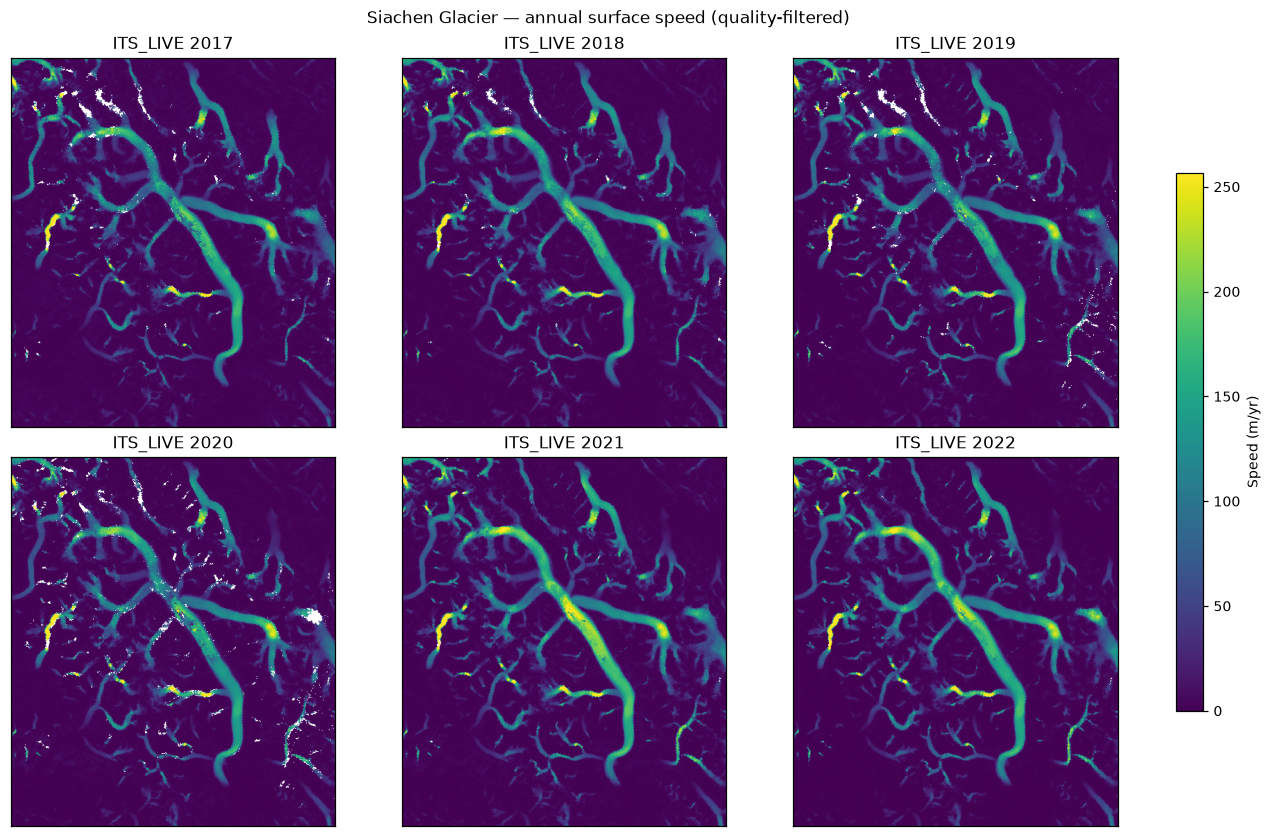

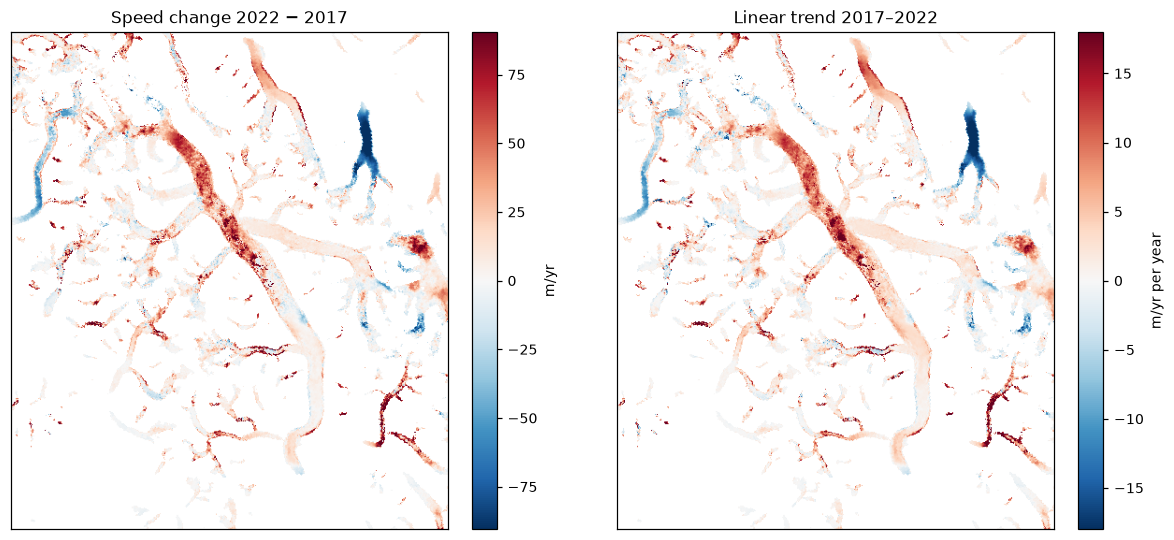

In [5]:
ext = None  # plot in pixel space; north is up for this projection near Siachen
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)
vmax = np.nanpercentile(vq[:, glacier], 99)
for ax, i in zip(axes.ravel(), range(len(YEARS))):
    im = ax.imshow(vq[i], cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"ITS_LIVE {YEARS[i]}"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.7, label="Speed (m/yr)")
fig.suptitle("Siachen Glacier — annual surface speed (quality-filtered)")
fig.savefig(FIGS / "its_live_annual_speed.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
lim = np.nanpercentile(np.abs(dv), 98)
im = axes[0].imshow(dv, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[0].set_title("Speed change 2022 − 2017"); fig.colorbar(im, ax=axes[0], label="m/yr")
lim = np.nanpercentile(np.abs(trend), 98)
im = axes[1].imshow(trend, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1].set_title("Linear trend 2017–2022"); fig.colorbar(im, ax=axes[1], label="m/yr per year")
for a in axes: a.set_xticks([]); a.set_yticks([])
fig.savefig(FIGS / "its_live_change_and_trend.png"); plt.show()

## Part B — NISAR GOFF
### B1. Find all GOFF pairs on our frame
Filename pattern: `NISAR_L2_PR_GOFF_<cycle>_<track>_<pass>_<frame>_…_<refStart>_<refEnd>_<secStart>_<secEnd>_…h5`.
Any new file you drop into `data/nisar/` with the same track/frame/pass is processed automatically.

In [6]:
pat = re.compile(r"NISAR_L2_PR_GOFF_(\d{3})_(\d{3})_([AD])_(\d{3})_.*?_(\d{8}T\d{6})_\d{8}T\d{6}_(\d{8}T\d{6})_\d{8}T\d{6}_")
pairs = []
for f in sorted(NISAR_DIR.rglob("*.h5")):
    m = pat.search(f.name)
    if not m:
        print("Skipping (unrecognised name):", f.name); continue
    cyc, trk, pas, frm, t0, t1 = m.groups()
    rec = dict(file=f, cycle=int(cyc), track=int(trk), pass_=pas, frame=int(frm),
               ref=dt.datetime.strptime(t0, "%Y%m%dT%H%M%S"), sec=dt.datetime.strptime(t1, "%Y%m%dT%H%M%S"))
    rec["days"] = (rec["sec"] - rec["ref"]).total_seconds() / 86400
    rec["on_frame"] = (rec["track"], rec["frame"], rec["pass_"]) == (NISAR_TRACK, NISAR_FRAME, NISAR_PASS)
    pairs.append(rec)
pairs_df = pd.DataFrame(pairs).sort_values("ref")
display(pairs_df[["file", "track", "frame", "pass_", "ref", "sec", "days", "on_frame"]].assign(file=lambda d: d.file.map(lambda p: p.name[:40] + "…")))
use = pairs_df[pairs_df.on_frame]
print(f"{len(use)} GOFF pair(s) on track {NISAR_TRACK} / frame {NISAR_FRAME} / {NISAR_PASS}")

,file,track,frame,pass_,ref,sec,days,on_frame
0,NISAR_L2_PR_GOFF_005_135_D_071_006_2000_…,135,71,D,2025-11-19 13:46:28,2025-12-01 13:46:29,12.000012,True


1 GOFF pair(s) on track 135 / frame 71 / D


### B2. Processing function (crop → cull → bias-correct → geometry → velocity)

**Geometry.** GOFF offsets are measured in radar directions:
- `alongTrackOffset` — displacement along the satellite's flight direction (horizontal unit vector **a**),
- `slantRangeOffset` — change in distance to the satellite (line-of-sight unit vector **l**, pointing target → sensor, so a positive offset means the surface moved *away*).

Assuming flow is parallel to the ground surface and neglecting its vertical component (a standard single-geometry approximation), the horizontal displacement **u** = (uₑ, uₙ) solves

$$\begin{bmatrix} a_e & a_n \\ -l_e & -l_n \end{bmatrix}\begin{bmatrix} u_e \\ u_n\end{bmatrix} = \begin{bmatrix} d_{az} \\ d_{rg}\end{bmatrix}$$

per pixel, using the unit vectors stored in the product's `radarGrid` cube. Velocity = **u** / Δt × 365.25.
*Limitation:* on steep slopes the vertical component leaks into the range offset — a second (ascending) geometry would remove this assumption.

In [7]:
G = "science/LSAR/GOFF/grids/frequencyA/pixelOffsets/"
RG = "science/LSAR/GOFF/metadata/radarGrid/"

def interp_radargrid(f, name, level, dst_transform, shape, crs):
    """Bilinear-resample one height level of a radarGrid cube onto the offset grid."""
    X = f[RG + "xCoordinates"][()]; Y = f[RG + "yCoordinates"][()]
    dx, dy = X[1] - X[0], Y[1] - Y[0]
    src_t = from_origin(X[0] - dx / 2, Y[0] - dy / 2, dx, -dy)
    out = np.full(shape, np.nan, "float32")
    reproject(f[RG + name][level].astype("float32"), out, src_transform=src_t, src_crs=crs,
              dst_transform=dst_transform, dst_crs=crs, resampling=Resampling.bilinear,
              src_nodata=np.nan, dst_nodata=np.nan)
    return out

def process_goff(rec, its_v_on_grid=None, snr_min=5.0, max_abs=30.0, med_tol=2.0, ref_height=5000.0):
    out = {"rec": rec}
    with h5py.File(rec["file"], "r") as f:
        epsg = int(f[G + "projection"][()]); crs = rasterio.crs.CRS.from_epsg(epsg)
        X = f[G + "xCoordinates"][()]; Y = f[G + "yCoordinates"][()]
        x0, y0, x1, y1 = aoi_bounds_in(crs)
        c0, c1 = np.searchsorted(X, x0), np.searchsorted(X, x1)
        r0, r1 = np.searchsorted(-Y, -y1), np.searchsorted(-Y, -y0)
        sl = np.s_[r0:r1, c0:c1]
        res = X[1] - X[0]
        transform = from_origin(X[c0] - res / 2, Y[r0] + res / 2, res, res)
        shape = (r1 - r0, c1 - c0)

        # --- choose the correlation layer with the most plausible, high-SNR pixels ---
        best = None
        for L in [l.decode() for l in f["science/LSAR/GOFF/grids/frequencyA/listOfLayers"][()]]:
            at = f[G + f"HH/{L}/alongTrackOffset"][sl].astype("f8")
            sr = f[G + f"HH/{L}/slantRangeOffset"][sl].astype("f8")
            snr = f[G + f"HH/{L}/snr"][sl].astype("f8")
            score = np.mean(np.isfinite(at) & (np.abs(at) < max_abs) & (np.abs(sr) < max_abs) & (snr >= snr_min))
            if best is None or score > best[0]:
                best = (score, L, at, sr, snr)
        score, layer, at, sr, snr = best
        mask = f[G + "mask"][sl]

        # --- geometry: pick the radarGrid height level closest to typical Siachen ice elevation ---
        h = f[RG + "heightAboveEllipsoid"][()]; lev = int(np.argmin(np.abs(h - ref_height)))
        ae = interp_radargrid(f, "alongTrackUnitVectorX", lev, transform, shape, crs)
        an = interp_radargrid(f, "alongTrackUnitVectorY", lev, transform, shape, crs)
        le = interp_radargrid(f, "losUnitVectorX", lev, transform, shape, crs)
        ln = interp_radargrid(f, "losUnitVectorY", lev, transform, shape, crs)
        inc = interp_radargrid(f, "incidenceAngle", lev, transform, shape, crs)

    # --- culling ---
    water = (mask // 100) == 1                      # first digit = water flag
    valid_mask = (mask != 255) & ~water
    keep = valid_mask & np.isfinite(at) & np.isfinite(sr) & (snr >= snr_min) & (np.abs(at) < max_abs) & (np.abs(sr) < max_abs)
    at = np.where(keep, at, np.nan); sr = np.where(keep, sr, np.nan)
    # local-median consistency: drop pixels that disagree with their 5×5 neighbourhood by > med_tol metres
    at_m, sr_m = nan_median_filter(at), nan_median_filter(sr)
    cons = (np.abs(at - at_m) <= med_tol) & (np.abs(sr - sr_m) <= med_tol)
    at = np.where(cons, at, np.nan); sr = np.where(cons, sr, np.nan)

    # --- stable-ground bias removal (rock identified from ITS_LIVE) ---
    if its_v_on_grid is not None:
        rock = (its_v_on_grid <= 3) & np.isfinite(at)
    else:
        rock = np.isfinite(at)
    bias_at, bias_sr = np.nanmedian(at[rock]), np.nanmedian(sr[rock])
    at, sr = at - bias_at, sr - bias_sr
    rock_scatter = float(np.nanstd(np.hypot(at[rock], sr[rock])))

    # --- solve for horizontal east/north displacement ---
    det = ae * (-ln) - an * (-le)
    ue = (at * (-ln) - an * sr) / det
    un = (ae * sr - at * (-le)) / det
    scale = 365.25 / rec["days"]
    ve, vn = ue * scale, un * scale
    speed = np.hypot(ve, vn)

    out.update(dict(layer=layer, layer_score=score, crs=crs, transform=transform, shape=shape,
                    ve=ve, vn=vn, speed=speed, at=at, sr=sr, inc=inc,
                    bias_at=bias_at, bias_sr=bias_sr, rock_px=int(rock.sum()), rock_noise_m=rock_scatter,
                    kept_pct=100 * np.isfinite(speed).mean()))
    return out
print("process_goff() defined")

process_goff() defined


### B3. Bring the ITS_LIVE baseline onto the NISAR grid (for rock mask & comparison)

In [8]:
def its_to_grid(arr2d, dst_transform, dst_crs, shape):
    out = np.full(shape, np.nan, "float32")
    reproject(arr2d.astype("float32"), out, src_transform=ITS_TRANSFORM, src_crs=ITS_CRS,
              dst_transform=dst_transform, dst_crs=dst_crs, resampling=Resampling.bilinear,
              src_nodata=np.nan, dst_nodata=np.nan)
    return out

# ITS_LIVE vx/vy are in the ESRI:102027 grid axes — rotate them into the NISAR (UTM) east/north axes
def rotate_its_vectors(vx, vy, dst_crs):
    t = Transformer.from_crs(ITS_CRS, dst_crs, always_xy=True)
    cx = ITS_TRANSFORM.c + ITS_TRANSFORM.a * vx.shape[1] / 2
    cy = ITS_TRANSFORM.f + ITS_TRANSFORM.e * vx.shape[0] / 2
    (x0, x1), (y0, y1) = t.transform([cx, cx + 1000], [cy, cy])
    ang = np.arctan2(y1 - y0, x1 - x0)          # angle of ITS x-axis in UTM
    return vx * np.cos(ang) - vy * np.sin(ang), vx * np.sin(ang) + vy * np.cos(ang), np.degrees(ang)

first = use.iloc[0]
with h5py.File(first.file, "r") as f:
    NISAR_CRS = rasterio.crs.CRS.from_epsg(int(f[G + "projection"][()]))
print("NISAR CRS:", NISAR_CRS)

NISAR CRS: EPSG:32643


### B4. Process every pair

In [9]:
results = []
for _, rec in use.iterrows():
    # quick dry run to get the grid, then the real run with the ITS_LIVE rock mask
    probe = process_goff(rec)
    its_med_grid = its_to_grid(np.where(np.isfinite(v_med), v_med, np.nan), probe["transform"], probe["crs"], probe["shape"])
    r = process_goff(rec, its_v_on_grid=its_med_grid)
    r["its_med_grid"] = its_med_grid
    tag = f"{rec.ref:%Y%m%d}_{rec.sec:%Y%m%d}"
    for k in ("ve", "vn", "speed"):
        save_tif(PROC_NISAR / f"nisar_{tag}_{k}.tif", r[k], r["transform"], r["crs"])
    results.append(r)

summary = pd.DataFrame([{
    "pair": f"{r['rec'].ref:%Y-%m-%d} → {r['rec'].sec:%Y-%m-%d}", "days": r["rec"].days,
    "layer": r["layer"], "kept_%": round(r["kept_pct"], 1),
    "bias_alongTrack_m": round(r["bias_at"], 2), "bias_slantRange_m": round(r["bias_sr"], 2),
    "rock_px": r["rock_px"], "rock_noise_m": round(r["rock_noise_m"], 2),
    "rock_noise_m_per_yr": round(r["rock_noise_m"] * 365.25 / r["rec"].days, 1),
    "glacier_median_speed_m_yr": round(float(np.nanmedian(r["speed"][r["its_med_grid"] >= 15])), 1),
    "glacier_p90_speed_m_yr": round(float(np.nanpercentile(r["speed"][(r["its_med_grid"] >= 15) & np.isfinite(r["speed"])], 90)), 1),
} for r in results])
summary.to_csv(RESULTS / "nisar_pairs_summary.csv", index=False)
summary

C:\Users\Dell\AppData\Local\Temp\ipykernel_22884\3171817122.py:51: RuntimeWarning: All-NaN slice encountered
  return np.nanmedian(sliding_window_view(p, (size, size)), axis=(-1, -2))


C:\Users\Dell\AppData\Local\Temp\ipykernel_22884\3171817122.py:51: RuntimeWarning: All-NaN slice encountered
  return np.nanmedian(sliding_window_view(p, (size, size)), axis=(-1, -2))


,pair,days,layer,kept_%,bias_alongTrack_m,bias_slantRange_m,rock_px,rock_noise_m,rock_noise_m_per_yr,glacier_median_speed_m_yr,glacier_p90_speed_m_yr
0,2025-11-19 → 2025-12-01,12.000012,layer2,51.8,-0.02,5.12,147881,0.87,26.5,47.4,110.9


### B5. Sanity check against ITS_LIVE
The periods do **not** overlap (ITS_LIVE 2017–22 annual vs NISAR 12-day winter window), so we do not expect identical numbers —
but the *spatial pattern* (where ice is fast vs slow) and *flow direction* should agree if the NISAR processing is right.

In [10]:
r = results[0]
ve_i, vn_i, rot = rotate_its_vectors(np.nanmedian(vxq, 0), np.nanmedian(vyq, 0), r["crs"])
its_ve = its_to_grid(ve_i, r["transform"], r["crs"], r["shape"])
its_vn = its_to_grid(vn_i, r["transform"], r["crs"], r["shape"])
its_sp = r["its_med_grid"]

sel = np.isfinite(r["speed"]) & np.isfinite(its_sp) & (its_sp >= 15)
corr = np.corrcoef(r["speed"][sel], its_sp[sel])[0, 1]
ratio = np.nanmedian(r["speed"][sel] / its_sp[sel])
# direction agreement (angle between NISAR and ITS_LIVE flow vectors) on clearly moving ice
fast = sel & (its_sp >= 40)
cosang = (r["ve"][fast] * its_ve[fast] + r["vn"][fast] * its_vn[fast]) / (r["speed"][fast] * np.hypot(its_ve[fast], its_vn[fast]))
angdiff = np.degrees(np.arccos(np.clip(cosang, -1, 1)))

check = pd.Series({
    "glacier pixels compared": int(sel.sum()),
    "speed correlation (Pearson r)": round(corr, 2),
    "median NISAR / ITS_LIVE speed ratio": round(ratio, 2),
    "fast-ice pixels (ITS_LIVE ≥ 40 m/yr)": int(fast.sum()),
    "median flow-direction difference (deg)": round(float(np.median(angdiff)), 1),
    "% fast-ice pixels within 30° of ITS_LIVE": round(float((angdiff <= 30).mean() * 100), 1),
    "ITS_LIVE→UTM axis rotation applied (deg)": round(rot, 2),
})
check.to_csv(RESULTS / "nisar_vs_its_live_check.csv", header=["value"])
check

C:\Users\Dell\AppData\Local\Temp\ipykernel_22884\4257062770.py:2: RuntimeWarning: All-NaN slice encountered
  ve_i, vn_i, rot = rotate_its_vectors(np.nanmedian(vxq, 0), np.nanmedian(vyq, 0), r["crs"])


glacier pixels compared                     71869.00
speed correlation (Pearson r)                   0.60
median NISAR / ITS_LIVE speed ratio             0.69
fast-ice pixels (ITS_LIVE ≥ 40 m/yr)        49560.00
median flow-direction difference (deg)          9.20
% fast-ice pixels within 30° of ITS_LIVE       88.90
ITS_LIVE→UTM axis rotation applied (deg)       13.15
dtype: float64

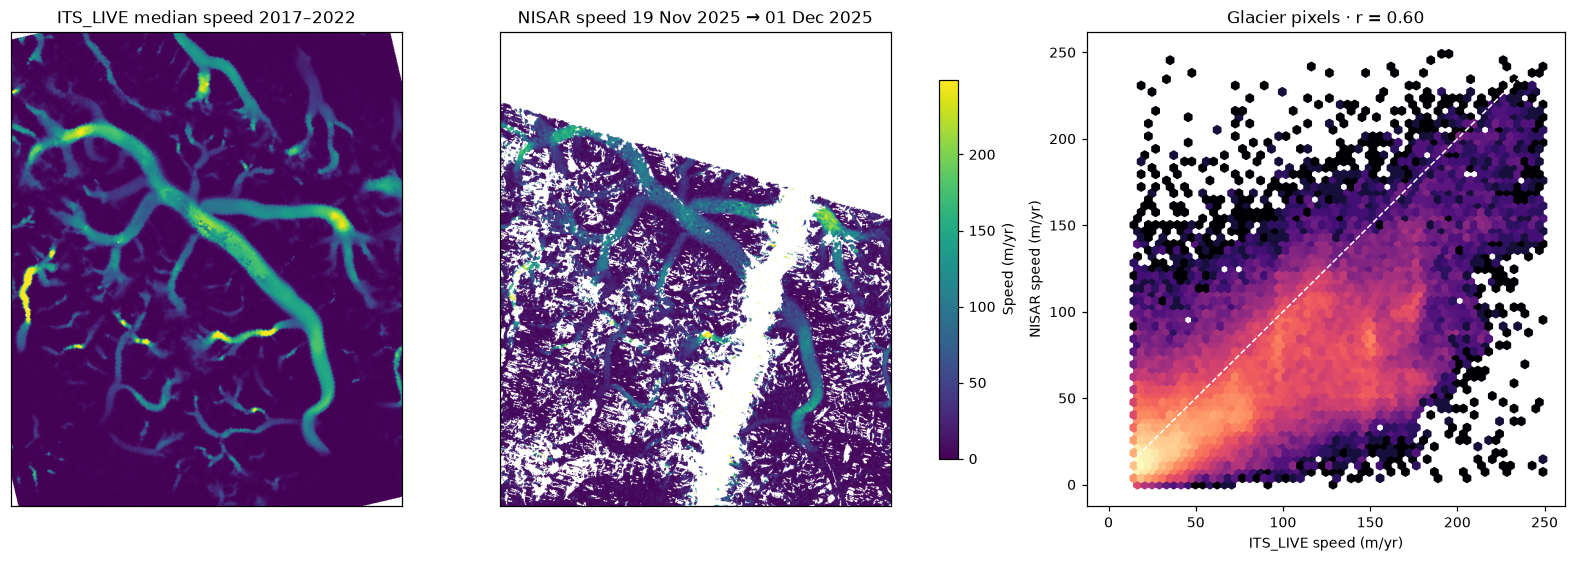

In [11]:
vmax = np.nanpercentile(its_sp[its_sp >= 15], 99)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
im = axes[0].imshow(its_sp, cmap="viridis", vmin=0, vmax=vmax); axes[0].set_title("ITS_LIVE median speed 2017–2022")
axes[1].imshow(r["speed"], cmap="viridis", vmin=0, vmax=vmax)
axes[1].set_title(f"NISAR speed {r['rec'].ref:%d %b %Y} → {r['rec'].sec:%d %b %Y}")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="Speed (m/yr)")
for a in axes[:2]: a.set_xticks([]); a.set_yticks([])
axes[2].hexbin(its_sp[sel], r["speed"][sel], gridsize=60, bins="log", cmap="magma", extent=(0, vmax, 0, vmax))
axes[2].plot([0, vmax], [0, vmax], "w--", lw=1)
axes[2].set_xlabel("ITS_LIVE speed (m/yr)"); axes[2].set_ylabel("NISAR speed (m/yr)")
axes[2].set_title(f"Glacier pixels · r = {corr:.2f}")
fig.savefig(FIGS / "nisar_vs_its_live_speed.png"); plt.show()

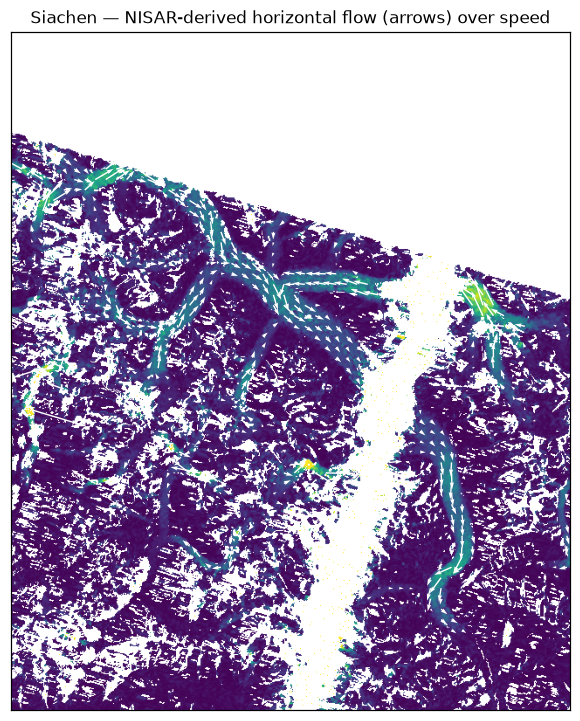

In [12]:
# Flow-direction arrows on top of NISAR speed
step = 12
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(r["speed"], cmap="viridis", vmin=0, vmax=vmax)
yy, xx = np.mgrid[0:r["shape"][0]:step, 0:r["shape"][1]:step]
ve_s, vn_s = r["ve"][::step, ::step], r["vn"][::step, ::step]
m = np.isfinite(ve_s) & (its_sp[::step, ::step] >= 20)
ax.quiver(xx[m], yy[m], ve_s[m], vn_s[m], color="white", scale=4000, width=0.0025)  # vn up = north
ax.set_title("Siachen — NISAR-derived horizontal flow (arrows) over speed")
ax.set_xticks([]); ax.set_yticks([])
fig.savefig(FIGS / "nisar_flow_arrows.png"); plt.show()

### B6. Coverage diagnostic — which parts of the glacier does each pair actually measure?
Two kinds of gaps are expected in a single NISAR pair:
- **Frame edge** — the top of the AOI lies outside frame 71 (mask = 255 plus a band of garbage offsets along the edge).
- **Range-gap stripe** — a north–south stripe with no correlation, where the instrument's receive gap falls in both acquisitions (this pair is *not dithered*, so the gap does not move between dates). Pairs from other dates (dithered) or an ascending track fill it.

Glacier ice measured by at least one pair: 59.6%


,pair,% measured: slow ice 15–40 m/yr,% measured: medium ice 40–80 m/yr,% measured: fast ice ≥80 m/yr
0,2025-11-19 → 2025-12-01,56.4,61.2,61.1


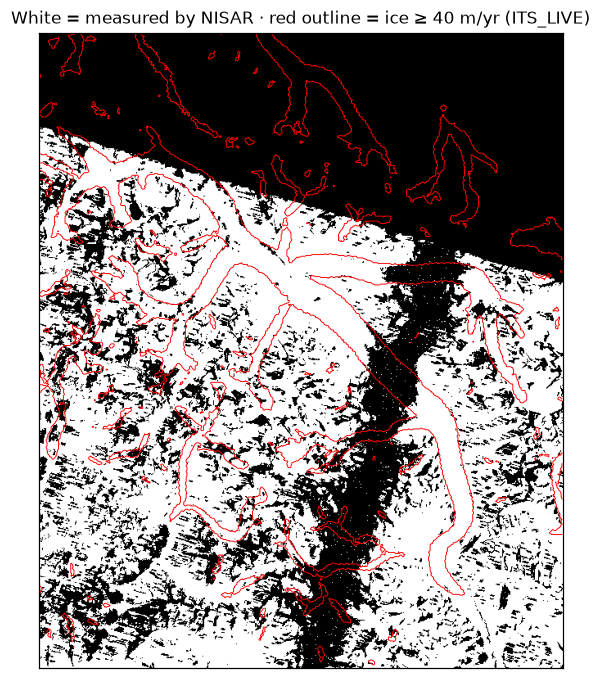

In [13]:
cov_rows = []
for r in results:
    its_g = r["its_med_grid"]
    row = {"pair": f"{r['rec'].ref:%Y-%m-%d} → {r['rec'].sec:%Y-%m-%d}"}
    for lo, hi, name in [(15, 40, "slow ice 15–40"), (40, 80, "medium ice 40–80"), (80, 1e9, "fast ice ≥80")]:
        s = (its_g >= lo) & (its_g < hi)
        row[f"% measured: {name} m/yr"] = round(100 * np.isfinite(r["speed"][s]).mean(), 1)
    cov_rows.append(row)
# combined coverage of all pairs together
anyvalid = np.any([np.isfinite(r["speed"]) for r in results], axis=0)
s = results[0]["its_med_grid"] >= 15
cov = pd.DataFrame(cov_rows)
cov.to_csv(RESULTS / "nisar_coverage.csv", index=False)
print(f"Glacier ice measured by at least one pair: {100*anyvalid[s].mean():.1f}%")
display(cov)

fig, ax = plt.subplots(figsize=(7, 7.5))
ax.imshow(np.where(anyvalid, 1, 0), cmap="gray", vmin=0, vmax=1)
ax.contour(results[0]["its_med_grid"] >= 40, [0.5], colors="red", linewidths=0.6)
ax.set_title("White = measured by NISAR · red outline = ice ≥ 40 m/yr (ITS_LIVE)")
ax.set_xticks([]); ax.set_yticks([])
fig.savefig(FIGS / "nisar_coverage.png"); plt.show()

## Summary — what was produced
| Output | Location |
|---|---|
| 42 cropped ITS_LIVE rasters, median speed, Δv, trend | `processed/its_live_siachen/` |
| NISAR east/north/speed GeoTIFFs per pair | `processed/nisar_siachen/` |
| Annual stats, NISAR pair summary, cross-check | `results/*.csv` |
| Figures | `results/figures/*.png` |

**Next (notebook 03):** once more GOFF pairs on track 135 / frame 71 are downloaded, re-run this notebook — each pair is processed automatically —
then build the NISAR time series (median stack, seasonal change) and the anomaly map.